# Vanilla, SFT and GRPO for graph navigation

Compare vanilla Qwen3-1.7B, SFT, SFT + GRPO and GRPO only on the same test questions. SFT and GRPO use separate training instances. Saved outputs show the completed experiment; this cleanup does not add a new GPU run.

<a id="setup"></a>
## 1. Setup

Use a fresh Kaggle T4 session with Internet enabled. The repository is cloned into the working folder. Set `INSTALL_DEPENDENCIES=True` for installation, restart the kernel, then set it to `False` and run from the top.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.metadata, tempfile, shutil

# GITHUB: clone into Path.cwd() on Kaggle; never create a repository-named subfolder.
CLONE_REPOSITORY = True
REPOSITORY_URL = "https://github.com/AlirezaAK2000/kg-navigation-rlvr.git"
REPOSITORY_BRANCH = "master"

# PATHS: None uses the cloned working directory and its saved data/.
PROJECT_ROOT_OVERRIDE = None  # alternate: Path("/kaggle/input/my-project/graph_rlvr")
DATA_ROOT_OVERRIDE = None  # e.g. Path("/kaggle/input/my-kg-dataset/data")
WORK_ROOT_OVERRIDE = None  # None -> /kaggle/working on Kaggle; local artifacts/grpo otherwise

# Execution and experiment settings.
INSTALL_DEPENDENCIES = False
REMOVE_UNUSED_MULTIMODAL_PACKAGES = True
RUN_GPU = True
SFT_EXAMPLES = 100  # required supervised warm start; reserved separately from GRPO
SFT_EPOCHS = 1
SFT_LEARNING_RATE = 2e-5
SFT_GRADIENT_ACCUMULATION_STEPS = 8
SHOW_PROGRESS = True  # questions, tool turns, sampled trajectories and optimizer steps
INSPECT_EXAMPLES = 3  # display stored episodes, without extra inference
INSPECT_OFFSET = (
    0  # choose another consecutive slice; same indices for vanilla/SFT/SFT+GRPO test outputs
)
RUN_FULL_TRAINING = True
RUN_GRPO_ONLY = True  # independent RL baseline, restored from the saved vanilla initialization
RUN_NAME = "kg_four_variants_seed41"
SELECTED_GPU = "0"  # expose one device BEFORE importing torch

MODEL_NAME = "Qwen/Qwen3-1.7B"
MODEL_REVISION_OVERRIDE = None  # immutable known revision selected below
TRAIN_HOPS = [1, 2, 3]
TRAIN_HOP_EXPOSURE = {1: 0.2, 2: 0.4, 3: 0.4}  # proportions of actual sampled question groups
EVAL_HOPS = [1, 2, 3, 4]
MAX_TRAIN_EXAMPLES = 1000  # GRPO pool cap AFTER reserving the separate SFT examples
TEST_EVAL_SIZE = (
    30  # same fixed test subset for all four variants; None uses all unique test instances
)
RELOAD_EVAL_SIZE = 3
SEED = 41

NUM_GENERATIONS = 8
LORA_R, LORA_ALPHA = 8, 16
GRADIENT_ACCUMULATION_STEPS = 8
LEARNING_RATE = 5e-6
MAX_TOOL_CALLS = 12  # four discovery/traversal pairs + submission need 9 calls
MAX_TURN_TOKENS = 128
MAX_COMPLETION_TOKENS = 1536  # all model + observation tokens after the initial prompt
MAX_PROMPT_TOKENS = 1024
MAX_CONTEXT_TOKENS = 3072
MAX_NEIGHBORS_PER_RESPONSE = 16
MAX_OBSERVATION_CHARS = 4000
INITIAL_TRAINING_STEPS = 20
SAVE_STEPS = 10
EVALUATE_EVERY_STEPS = 0  # test monitoring after every optimizer step in smoke/full; 0 disables
PERIODIC_EVAL_SIZE = 6
GRPO_ONLY_RESUME_FROM_CHECKPOINT = None
RESUME_FROM_CHECKPOINT = None  # full checkpoint-* folder, not an adapter-only export
MAKE_ZIP = True

IS_KAGGLE = Path("/kaggle/working").exists()
PROJECT_ROOT = (
    Path(PROJECT_ROOT_OVERRIDE)
    if PROJECT_ROOT_OVERRIDE
    else next(
        (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/kg_rlvr").exists()), Path.cwd()
    )
)
if CLONE_REPOSITORY and not (PROJECT_ROOT / "src/kg_rlvr").exists():
    with tempfile.TemporaryDirectory() as checkout:
        subprocess.check_call(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                REPOSITORY_BRANCH,
                REPOSITORY_URL,
                checkout,
            ]
        )
        shutil.copytree(checkout, PROJECT_ROOT, dirs_exist_ok=True)
DATA_ROOT = Path(DATA_ROOT_OVERRIDE or PROJECT_ROOT / "data")
WORK_ROOT = Path(
    WORK_ROOT_OVERRIDE or ("/kaggle/working" if IS_KAGGLE else PROJECT_ROOT / "artifacts/grpo")
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ["CUDA_VISIBLE_DEVICES"] = SELECTED_GPU
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "kg_grpo_matplotlib"))
os.environ.setdefault("HF_HOME", str(WORK_ROOT / "hf_cache"))
WORK_ROOT.mkdir(parents=True, exist_ok=True)
RUN_ROOT = WORK_ROOT / "runs" / RUN_NAME
RUN_ROOT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT = WORK_ROOT / "checkpoints" / RUN_NAME
VARIANT_DIRS = {
    name: RUN_ROOT / "variants" / name for name in ["vanilla", "sft", "sft_grpo", "grpo_only"]
}
EVALUATION_DIR = VARIANT_DIRS["sft_grpo"] / "evaluation"
ADAPTER_DIR = VARIANT_DIRS["sft_grpo"] / "adapter"
INITIAL_ADAPTER_DIR = VARIANT_DIRS["vanilla"] / "initial_adapter"
SFT_GRPO_CHECKPOINT_ROOT = CHECKPOINT_ROOT / "sft_grpo"
GRPO_ONLY_CHECKPOINT_ROOT = CHECKPOINT_ROOT / "grpo_only"
print(
    f"Project: {PROJECT_ROOT}\nData: {DATA_ROOT}\nWorking outputs: {WORK_ROOT}\nSingle GPU selection: {SELECTED_GPU}"
)


Project already present in /kaggle/working; skipping clone (no automatic pull).
Project: /kaggle/working
Data: /kaggle/working/data
Working outputs: /kaggle/working
Single GPU selection: 0


In [2]:
if INSTALL_DEPENDENCIES:
    if not IS_KAGGLE:
        raise RuntimeError(
            "Automatic CUDA installation is scoped to a fresh Kaggle session. For local CPU checks use requirements.txt; inspect requirements-grpo.txt separately."
        )
    if REMOVE_UNUSED_MULTIMODAL_PACKAGES:
        subprocess.check_call(
            [
                sys.executable,
                "-m",
                "pip",
                "uninstall",
                "-y",
                "torchvision",
                "torchaudio",
                "torchcodec",
                "librosa",
            ]
        )
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--upgrade",
            "torch==2.6.0",
            "--index-url",
            "https://download.pytorch.org/whl/cu124",
        ]
    )
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--upgrade",
            "-r",
            str(PROJECT_ROOT / "requirements-grpo.txt"),
        ]
    )
    print("Installation complete. Restart the kernel before continuing.")
from kg_rlvr.training.grpo import dependency_versions, MODEL_REVISIONS, PINS

MODEL_REVISION = MODEL_REVISION_OVERRIDE or MODEL_REVISIONS[MODEL_NAME]
print("Model:", MODEL_NAME, MODEL_REVISION)
print("Installed:", dependency_versions())


Requested pins: {
  "torch": "2.6.0",
  "transformers": "5.3.0",
  "trl": "1.8.0",
  "peft": "0.18.1",
  "accelerate": "1.10.1",
  "bitsandbytes": "0.49.2",
  "datasets": "4.8.3",
  "jmespath": "1.0.1",
  "numpy": "1.26.4",
  "pandas": "2.2.3",
  "pyarrow": "21.0.0",
  "rdflib": "7.6.0",
  "pyparsing": "3.2.3"
}
Installed: {
  "torch": "2.6.0+cu124",
  "transformers": "5.3.0",
  "trl": "1.8.0",
  "peft": "0.18.1",
  "accelerate": "1.10.1",
  "bitsandbytes": "0.49.2",
  "datasets": "4.8.3",
  "jmespath": "1.0.1",
  "numpy": "1.26.4",
  "pandas": "2.2.3",
  "pyarrow": "21.0.0",
  "rdflib": "7.6.0",
  "pyparsing": "3.2.3",
  "tokenizers": "0.22.2",
  "huggingface-hub": "1.33.0",
  "matplotlib": "3.9.4",
  "psutil": "7.2.2",
  "tqdm": "4.67.3"
}
Selected model/revision: Qwen/Qwen3-1.7B 70d244cc86ccca08cf5af4e1e306ecf908b1ad5e


<a id="hardware"></a>
## 2. Runtime

One GPU is used. CPU execution explores the data and skips model training.

In [3]:
import gc, math, random, platform, time
import warnings

with warnings.catch_warnings(record=True) as dependency_notices:
    warnings.simplefilter("always", UserWarning)
    import pandas as pd
import torch
import psutil
from IPython.display import display, Markdown, HTML
from kg_rlvr.training.grpo import memory_snapshot, fingerprint_inputs, native_bf16_supported
from kg_rlvr.training.environment import EpisodeLimits, GraphEnvironment, TOOL_SCHEMAS, REWARD_SPEC
from kg_rlvr.data import load_tasks, public_prompt

try:
    inventory = subprocess.run(
        ["nvidia-smi", "--query-gpu=index,name,memory.total,driver_version", "--format=csv"],
        text=True,
        capture_output=True,
        check=False,
    )
    print(inventory.stdout.strip() or "nvidia-smi inventory unavailable")
except FileNotFoundError:
    print("nvidia-smi unavailable on this machine")
HAS_CUDA = torch.cuda.is_available()
RUN_MODEL = RUN_GPU and HAS_CUDA
hardware = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cuda_runtime": torch.version.cuda,
    "visible_cuda_devices": torch.cuda.device_count(),
    "system_available_gib": psutil.virtual_memory().available / 2**30,
}
if HAS_CUDA:
    properties = torch.cuda.get_device_properties(0)
    hardware.update(
        gpu_name=properties.name,
        gpu_vram_gib=properties.total_memory / 2**30,
        gpu_capability=torch.cuda.get_device_capability(0),
        bf16_native_supported=native_bf16_supported(),
    )
display(pd.Series(hardware, name="runtime hardware").to_frame())
if dependency_notices:
    display(pd.DataFrame({"environment notice": [str(w.message) for w in dependency_notices]}))
MEMORY = [memory_snapshot("before_model")]
if not RUN_MODEL:
    display(Markdown("**CPU mode:** data exploration only; model execution is skipped."))
LIMITS = EpisodeLimits(
    MAX_TOOL_CALLS,
    MAX_NEIGHBORS_PER_RESPONSE,
    MAX_OBSERVATION_CHARS,
    MAX_TURN_TOKENS,
    MAX_COMPLETION_TOKENS,
    MAX_PROMPT_TOKENS,
    MAX_CONTEXT_TOKENS,
)
random.seed(SEED)
torch.manual_seed(SEED)


index, name, memory.total [MiB], driver_version
0, Tesla T4, 15360 MiB, 580.178.04
1, Tesla T4, 15360 MiB, 580.178.04


,runtime hardware
python,3.13.15
torch,2.6.0+cu124
cuda_runtime,12.4
visible_cuda_devices,1
system_available_gib,29.588024
gpu_name,Tesla T4
gpu_vram_gib,14.562195
gpu_capability,"(7, 5)"
bf16_native_supported,False


<a id="data"></a>
## 3. Data and stage separation

Load the saved questions and merge paraphrases. Reserve 100 SFT instances, use the remaining pool for GRPO, and evaluate every variant on the same 30 test questions. Training exposure is 20% / 40% / 40% across hops 1 / 2 / 3.

In [ ]:
from collections import Counter
from dataclasses import asdict
from kg_rlvr.training.sampling import (
    exposure_schedule,
    partition_training_tasks,
    check_stage_separation,
)
from kg_rlvr.training.sft import build_demonstration
import hashlib

INPUT_SHA256 = fingerprint_inputs(DATA_ROOT)
graph, store = load_tasks(
    DATA_ROOT, max_tool_calls=MAX_TOOL_CALLS
)
# Reference tools validate each SFT candidate before it is reserved. No model is run.
sft_demo_cache = {}


def check_sft_candidate(qid):
    sft_demo_cache[qid] = build_demonstration(store, qid, LIMITS)


sft_ids, train_ids, partition_report = partition_training_tasks(
    store,
    TRAIN_HOPS,
    sft_count=SFT_EXAMPLES,
    hop_weights=TRAIN_HOP_EXPOSURE,
    max_grpo_examples=MAX_TRAIN_EXAMPLES,
    seed=SEED,
    sft_candidate_check=check_sft_candidate,
)
SFT_DEMONSTRATIONS = [sft_demo_cache[qid] for qid in sft_ids]
test_ids = store.select(
    "test", EVAL_HOPS, TEST_EVAL_SIZE, SEED + 1, unique_instances=True, balanced=True
)
partition_report["all_stage_check"] = check_stage_separation(
    store, {"sft": sft_ids, "grpo": train_ids, "test": test_ids}
)
partition_report["sft_ids"] = sft_ids
partition_report["grpo_ids"] = train_ids
STAGE_PARTITION_SHA256 = hashlib.sha256(
    json.dumps(partition_report, sort_keys=True).encode()
).hexdigest()
(RUN_ROOT / "stage_partition.json").write_text(json.dumps(partition_report, indent=2) + "\n")
for stage, ids in [("sft", sft_ids), ("grpo", train_ids)]:
    stage_dir = RUN_ROOT / "training_partitions"
    stage_dir.mkdir(parents=True, exist_ok=True)
    (stage_dir / f"{stage}.jsonl").write_text(
        "".join(json.dumps(store.record(qid)) + "\n" for qid in ids)
    )
SFT_RUN_DIR = VARIANT_DIRS["sft"]
SFT_RUN_DIR.mkdir(parents=True, exist_ok=True)
(SFT_RUN_DIR / "demonstrations.jsonl").write_text(
    "".join(json.dumps(demo) + "\n" for demo in SFT_DEMONSTRATIONS)
)
display(pd.Series(partition_report["all_stage_check"], name="verified stage separation").to_frame())
display(
    pd.DataFrame(
        [
            {
                "subset": label,
                "questions": len(ids),
                "hops": dict(Counter(store.record(qid)["hop_count"] for qid in ids)),
            }
            for label, ids in [
                ("SFT reserved", sft_ids),
                ("GRPO train", train_ids),
                ("fixed test (all four variants)", test_ids),
            ]
        ]
    )
)
print(f"Graph: {len(graph.entities)} entities, {len(graph.triples)} stored triples")
print(
    "Selected train rows are real existing query instances; a configured maximum larger than the available pool is reported, not filled with invented rows."
)
display(Markdown("**Example model-visible prompt (no gold program or answer metadata):**"))
display(pd.DataFrame(store.prompt(train_ids[0])))
fixed_selection = {"sft_ids": sft_ids, "train_ids": train_ids, "test_ids": test_ids}
(RUN_ROOT / "fixed_task_ids.json").write_text(json.dumps(fixed_selection, indent=2) + "\n")
# Preserve saved question IDs in exported selections.
display(pd.DataFrame(store.selection_statistics))
(RUN_ROOT / "question_selection.json").write_text(
    json.dumps(store.selection_statistics, indent=2) + "\n"
)
for split in ["train", "test"]:
    questions = store.select(split, [1, 2, 3, 4], seed=SEED, unique_instances=False)
    export_dir = RUN_ROOT / "selected_dataset" / "rl"
    export_dir.mkdir(parents=True, exist_ok=True)
    (export_dir / f"{split}.jsonl").write_text(
        "".join(json.dumps(store.record(qid)) + "\n" for qid in questions)
    )
exposure_preview = []
for phase, steps in [("full", INITIAL_TRAINING_STEPS)]:
    planned = exposure_schedule(
        store,
        train_ids,
        steps * (GRADIENT_ACCUMULATION_STEPS // NUM_GENERATIONS),
        TRAIN_HOP_EXPOSURE,
        SEED,
    )
    exposure_preview.append(
        {
            "phase": phase,
            "question_groups": len(planned),
            "groups_by_hop": dict(Counter(store.record(qid)["hop_count"] for qid in planned)),
            "sampled_trajectories": len(planned) * NUM_GENERATIONS,
        }
    )
display(pd.DataFrame(exposure_preview))
(RUN_ROOT / "training_exposure_preview.json").write_text(
    json.dumps(exposure_preview, indent=2) + "\n"
)
print(
    "20/40/40 exposure means 1/2/2 question groups in every five groups; partial blocks are rounded by interleaving."
)

from kg_rlvr.training.artifacts import (
    evaluate_variant,
    save_json,
    save_comparison,
    read_rows,
    collect_training_logs,
)

RUN_METADATA = {
    "model_name": MODEL_NAME,
    "revision": MODEL_REVISION,
    "hardware": hardware,
    "versions": dependency_versions(),
    "source_sha256": INPUT_SHA256,
    "limits": asdict(LIMITS),
    "evaluation_split": "test",
    "evaluation_task_ids": test_ids,
    "stage_partition_sha256": STAGE_PARTITION_SHA256,
    "variants": ["vanilla", "sft", "sft_grpo", "grpo_only"],
    "grpo_only_enabled": RUN_GRPO_ONLY,
}
save_json(RUN_ROOT / "run_environment.json", RUN_METADATA)


,verified stage separation
disjoint,True
checked,"[question_ids, query_instances, public_prompts]"
counts,"{'sft': 100, 'grpo': 833, 'test': 30}"


,subset,questions,hops
0,SFT reserved,100,"{2: 40, 1: 20, 3: 40}"
1,GRPO train,833,"{1: 297, 2: 269, 3: 267}"
2,fixed test (all four variants),30,"{1: 8, 2: 8, 3: 7, 4: 7}"


Graph: 2000 entities, 5000 stored triples
Selected train rows are real existing query instances; a configured maximum larger than the available pool is reported, not filled with invented rows.


**Example model-visible prompt (no gold program or answer metadata):**

,role,content
0,system,Navigate the fictional research graph to answe...
1,user,Question: Which field does Project Phanuvlym 0...


,split,hop_count,questions,unique_instances
0,train,1,633,317
1,train,2,617,309
2,train,3,613,307
3,train,4,586,293
4,test,1,249,125
5,test,2,249,125
6,test,3,249,125
7,test,4,236,118


,phase,question_groups,groups_by_hop,sampled_trajectories
0,full,20,"{2: 8, 3: 8, 1: 4}",160


20/40/40 exposure means 1/2/2 question groups in every five groups; partial blocks are rounded by interleaving.


<a id="tools"></a>
## 4. Environment and reward

Tools expose relations, traverse neighbors and submit one discovered entity. Each turn contains one tool call. The model receives no gold answers.

**Return = correct submission + 0.2 × answer retrieved.** The retrieval bonus is awarded once; reaching an answer without submitting it earns no correctness reward.

In [5]:
fixture_id = store.select("train", [min(TRAIN_HOPS)], count=1, seed=SEED)[0]
fixture = store.record(fixture_id)
fixture_env = GraphEnvironment(graph, fixture["start_entity"], LIMITS)
fixture_path = fixture["gold_entity_paths"][0]

# Execute a saved reference route to demonstrate the tool interface.
for head, relation, tail in zip(fixture_path, fixture["relation_path"], fixture_path[1:]):
    fixture_env.get_neighbors(head, relation)
fixture_env.submit_answer(fixture_path[-1])
display(pd.DataFrame(fixture_env.trajectory))
print("Available tools:", [tool["function"]["name"] for tool in TOOL_SCHEMAS])


,index,name,arguments,observation
0,1,get_neighbors,"{'entity_id': 'researcher_000562', 'relation_i...","{'ok': True, 'entity_id': 'researcher_000562',..."
1,2,submit_answer,{'entity_id': 'project_000257'},"{'ok': True, 'submitted': 'project_000257', 'e..."


Non-model tool contract checks passed. Schema tools: ['get_relations', 'get_neighbors', 'submit_answer']


<a id="model"></a>
## 5. Model

Load the pinned Qwen3-1.7B revision with NF4 quantization and LoRA. Adapter storage stays FP32; T4 computation uses FP16.

In [6]:
from kg_rlvr.training.grpo import load_qlora, export_adapter, lora_fingerprint
from kg_rlvr.training.rollouts import QwenChatCodec, progress_bar

model, tokenizer, COMPUTE_DTYPE = None, None, None
if RUN_MODEL:
    try:
        model, tokenizer, COMPUTE_DTYPE = load_qlora(
            MODEL_NAME, MODEL_REVISION, LORA_R, LORA_ALPHA, show_progress=SHOW_PROGRESS
        )
    except torch.OutOfMemoryError:
        gc.collect()
        torch.cuda.empty_cache()
        raise RuntimeError(
            "Model load ran out of memory. Apply the documented smaller-budget/model fallback explicitly; no replacement model has been loaded."
        )
    INITIAL_LORA_SHA256 = lora_fingerprint(model)
    export_adapter(
        model,
        tokenizer,
        INITIAL_ADAPTER_DIR,
        {
            **RUN_METADATA,
            "kind": "untrained_initial_adapter",
            "initial_lora_sha256": INITIAL_LORA_SHA256,
        },
    )
    MEMORY.append(memory_snapshot("after_qlora_load"))
else:
    print("Qwen weights and NF4 initialization not run: no enabled CUDA model runtime.")


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

The tied weights mapping and config for this model specifies to tie model.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

trainable params: 8,716,288 || all params: 2,040,456,192 || trainable%: 0.4272


Checking model prompts:   0%|          | 0/963 [00:00<?, ?question/s]

Model Qwen/Qwen3-1.7B revision 70d244cc86ccca08cf5af4e1e306ecf908b1ad5e dtype torch.float16 max public prompt tokens 617


<a id="baseline"></a>
## 6. Vanilla baseline

Disable the untrained adapter and evaluate before fine-tuning.

In [7]:
from kg_rlvr.training.rollouts import evaluate_policy

BASE_METRICS, BASE_TRACES = None, []
if RUN_MODEL:
    with model.disable_adapter():
        BASE_METRICS, BASE_TRACES = evaluate_variant(
            model,
            tokenizer,
            store,
            test_ids,
            LIMITS,
            RUN_ROOT,
            "vanilla",
            show_progress=SHOW_PROGRESS,
        )
    display(pd.Series(BASE_METRICS, name="measured vanilla test performance").to_frame())
    MEMORY.append(memory_snapshot("after_baseline"))
    save_json(VARIANT_DIRS["vanilla"] / "memory_snapshots.json", [MEMORY[-1]])
    if not any(
        event["name"] == "get_neighbors" and event["observation"].get("ok")
        for trace in BASE_TRACES
        for event in trace["tool_events"]
    ):
        print(
            "Vanilla executed no valid neighbor tools. No working baseline tool use is claimed; supervised demonstrations will provide valid action targets."
        )
else:
    print("Vanilla test evaluation not run; no baseline accuracy is reported.")


test:   0%|          | 0/30 [00:00<?, ?question/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


,measured vanilla test performance
episodes,30
mean_reward,0.133333
total_reward,4.0
mean_reward_by_hop,"{'1': 0.5, '2': 0.0, '3': 0.0, '4': 0.0}"
mean_training_reward,0.16
total_training_reward,4.8
mean_training_reward_by_hop,"{'1': 0.6, '2': 0.0, '3': 0.0, '4': 0.0}"
retrieval_success_rate,0.133333
mean_retrieval_reward,0.026667
accuracy,0.133333


### Inspect vanilla outputs

Cards preserve the input prompt, raw model output, tool calls and observations in recorded order.

In [8]:
from IPython.display import HTML
from kg_rlvr.training.inspection import render_traces_html

display(HTML(render_traces_html(BASE_TRACES, label="Vanilla baseline · test",
    count=INSPECT_EXAMPLES, offset=INSPECT_OFFSET, tokenizer=tokenizer)))


<a id="sft"></a>
## 7. SFT warm start

Train one epoch on the reserved demonstrations. Only assistant tokens receive labels; prompts and observations are masked.

Preparing SFT tool demonstrations:   0%|          | 0/100 [00:00<?, ?question/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Step,Training Loss
1,0.075839
2,0.059532
3,0.025192
4,0.003349
5,0.027549
6,0.027284
7,0.034481
8,0.030293
9,0.015939
10,0.005051


,loss,grad_norm,learning_rate,epoch,step
0,0.075839,0.164766,0.00002,0.08,1
1,0.059532,0.077916,0.00002,0.16,2
2,0.025192,0.065382,0.00002,0.24,3
3,0.003349,0.064907,0.00002,0.32,4
4,0.027549,0.069330,0.00002,0.40,5
5,0.027284,0.075197,0.00002,0.48,6
6,0.034481,0.099050,0.00002,0.56,7
7,0.030293,0.088571,0.00002,0.64,8
8,0.015939,0.095193,0.00002,0.72,9
9,0.005051,0.031522,0.00002,0.80,10


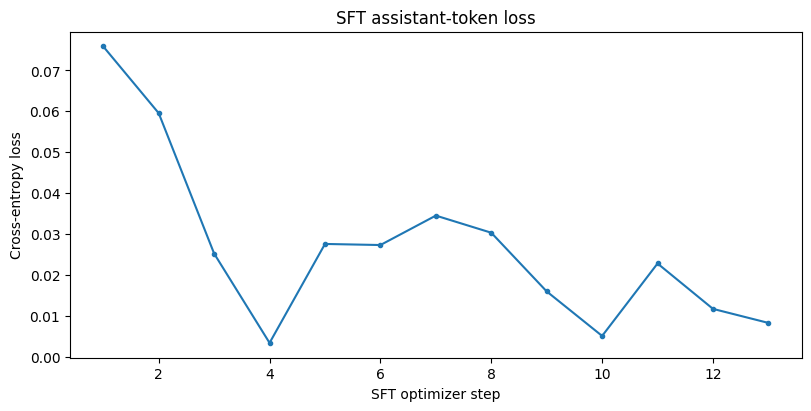

,verified supervised warm start
optimizer_steps,13
changed_lora_tensors,392
max_lora_weight_delta,0.000262
finite_losses,True
checkpoint,/kaggle/working/checkpoints/kg_four_variants_s...
precision,"{'trainable_dtype': 'torch.float32', 'trainabl..."
stage,verified_smoke_update
system_available_gib,27.691048
cuda_available,True
allocated_gib,3.112487


In [9]:
from kg_rlvr.training.sft import encode_demonstrations, build_sft_trainer
from kg_rlvr.training.grpo import lora_snapshot, summarize_training, export_adapter, training_manifest
SFT_RESULT, sft_trainer = None, None
SFT_WARM_START = {"enabled": False, "reserved_sft_ids": sft_ids, "stage_partition_sha256": STAGE_PARTITION_SHA256}
SFT_CONFIG = {"epochs": SFT_EPOCHS, "examples": SFT_EXAMPLES, "learning_rate": SFT_LEARNING_RATE,
    "accumulation": SFT_GRADIENT_ACCUMULATION_STEPS, "loss": "assistant_only_causal_lm"}
if RUN_MODEL:
    sft_dir = CHECKPOINT_ROOT / "sft"
    if sft_dir.exists() and any(sft_dir.iterdir()):
        raise FileExistsError("SFT output already exists; choose a fresh RUN_NAME to preserve measured evidence")
    sft_rows = encode_demonstrations(store, SFT_DEMONSTRATIONS, tokenizer, LIMITS, show_progress=SHOW_PROGRESS)
    sft_manifest = {"training_kind": "SFT", "model_name": MODEL_NAME, "revision": MODEL_REVISION,
        "task_ids": sft_ids, "configuration": SFT_CONFIG, "stage_partition_sha256": STAGE_PARTITION_SHA256,
        "source_sha256": INPUT_SHA256, "trainable_parameter_dtype": "torch.float32",
        "versions": dependency_versions()}
    sft_dir.mkdir(parents=True, exist_ok=True)
    (sft_dir / "run_manifest.json").write_text(json.dumps(sft_manifest, indent=2) + "\n")
    sft_trainer = build_sft_trainer(model, tokenizer, sft_rows, sft_dir, epochs=SFT_EPOCHS,
        accumulation=SFT_GRADIENT_ACCUMULATION_STEPS, learning_rate=SFT_LEARNING_RATE, seed=SEED,
        show_progress=SHOW_PROGRESS, diagnostics_dir=SFT_RUN_DIR / "training/sft")
    before_sft = lora_snapshot(model)
    torch.cuda.reset_peak_memory_stats()
    try:
        sft_train_result = sft_trainer.train()
        SFT_RESULT = summarize_training(model, before_sft, sft_trainer)
        SFT_RESULT.update(train_loss=float(sft_train_result.training_loss), examples=len(sft_rows), epochs=SFT_EPOCHS)
        model = sft_trainer.accelerator.unwrap_model(sft_trainer.model)
        export_adapter(model, tokenizer, SFT_RUN_DIR / "adapter", sft_manifest, extra={"verified_result": SFT_RESULT})
        SFT_WARM_START = {"enabled": True, "reserved_sft_ids": sft_ids,
            "stage_partition_sha256": STAGE_PARTITION_SHA256, "configuration": SFT_CONFIG,
            "adapter_sha256": {name: digest for name, digest in fingerprint_inputs(SFT_RUN_DIR / "adapter").items()
                               if name in {"adapter_config.json", "adapter_model.safetensors"}}}
        (SFT_RUN_DIR / "training_result.json").write_text(json.dumps(SFT_RESULT, indent=2) + "\n")
    except Exception as error:
        save_json(SFT_RUN_DIR / "status.json", {"variant": "sft", "status": "training_failed", "error": repr(error)})
        (SFT_RUN_DIR / "failure.json").write_text(json.dumps({"error": repr(error), "configuration": SFT_CONFIG}, indent=2) + "\n")
        raise  # never start GRPO after failed supervised training
    finally:
        collect_training_logs(SFT_RUN_DIR, [sft_dir])
        del before_sft
    for name in ["trainer_metrics.jsonl", "step_metrics.jsonl", "precision_checks.jsonl", "run_manifest.json"]:
        if (sft_dir / name).is_file():
            shutil.copy2(sft_dir / name, SFT_RUN_DIR / name)
    sft_logs = pd.DataFrame([row for row in sft_trainer.state.log_history if "loss" in row])
    display(sft_logs)
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    ax.plot(sft_logs.step, sft_logs.loss, marker=".")
    ax.set(title="SFT assistant-token loss", xlabel="SFT optimizer step", ylabel="Cross-entropy loss")
    (SFT_RUN_DIR / "figures").mkdir(exist_ok=True)
    fig.savefig(SFT_RUN_DIR / "figures/sft_loss.png", bbox_inches="tight"); plt.show(); plt.close(fig)
    sft_trainer.optimizer = None; sft_trainer.lr_scheduler = None
    sft_trainer.accelerator.free_memory()
    sft_trainer = None
    model.zero_grad(set_to_none=True)
    del sft_rows
    gc.collect(); torch.cuda.empty_cache()
    MEMORY.append(memory_snapshot("after_verified_sft"))
    display(pd.Series(SFT_RESULT, name="verified supervised warm start").to_frame())
else:
    print("SFT training not executed in CPU preflight. GRPO requires a verified SFT warm start.")


### SFT evaluation

Save test performance before starting GRPO.

In [10]:
SFT_METRICS, SFT_TRACES = None, []
if RUN_MODEL and SFT_RESULT is not None:
    SFT_METRICS, SFT_TRACES = evaluate_variant(model, tokenizer, store, test_ids, LIMITS,
        RUN_ROOT, "sft", show_progress=SHOW_PROGRESS, training_result=SFT_RESULT)
    display(pd.Series(SFT_METRICS, name="measured SFT test performance").to_frame())
    display(HTML(render_traces_html(SFT_TRACES, label="SFT · test", count=INSPECT_EXAMPLES,
        offset=INSPECT_OFFSET, tokenizer=tokenizer)))
    MEMORY.append(memory_snapshot("after_sft_only_evaluation"))
    save_json(SFT_RUN_DIR / "memory_snapshots.json", [MEMORY[-1]])
else:
    print("SFT-only evaluation not run; no SFT performance claim is available.")


test:   0%|          | 0/30 [00:00<?, ?question/s]

,measured SFT test performance
episodes,30
mean_reward,0.533333
total_reward,16.0
mean_reward_by_hop,"{'1': 0.5, '2': 0.75, '3': 0.5714285714285714,..."
mean_training_reward,0.666667
total_training_reward,20.0
mean_training_reward_by_hop,"{'1': 0.6749999999999999, '2': 0.8999999999999..."
retrieval_success_rate,0.666667
mean_retrieval_reward,0.133333
accuracy,0.533333


<a id="grpo"></a>
## 8. GRPO setup

Eight sampled trajectories form one question group. With microbatch 1 and accumulation 8, each optimizer update uses one group. TRL computes advantages and loss; the rollout executes the tools and masks observation tokens.

Identical group rewards give zero advantages and are logged without blocking training. The example learning rate is not tuned.

In [ ]:
from kg_rlvr.training.grpo import (
    build_trainer,
    training_manifest,
    export_adapter,
    reload_adapter_in_place,
)

EXPERIMENT_CONFIG = {
    "model_name": MODEL_NAME,
    "revision": MODEL_REVISION,
    "train_hops": TRAIN_HOPS,
    "eval_hops": EVAL_HOPS,
    "num_generations": NUM_GENERATIONS,
    "sft": {
        "enabled": True,
        "examples": SFT_EXAMPLES,
        "epochs": SFT_EPOCHS,
        "learning_rate": SFT_LEARNING_RATE,
        "accumulation": SFT_GRADIENT_ACCUMULATION_STEPS,
    },
    "stage_partition_sha256": STAGE_PARTITION_SHA256,
    "supervised_warm_start": SFT_WARM_START,
    "evaluation_split": "test",
    "evaluation_task_ids": test_ids,
    "comparison_variants": ["vanilla", "sft", "sft_grpo", "grpo_only"],
    "train_hop_exposure": TRAIN_HOP_EXPOSURE,
    "reward_spec": REWARD_SPEC,
    "microbatch": 1,
    "gradient_accumulation": GRADIENT_ACCUMULATION_STEPS,
    "unique_questions_per_update": GRADIENT_ACCUMULATION_STEPS // NUM_GENERATIONS,
    "learning_rate": LEARNING_RATE,
    "lora_r": LORA_R,
    "lora_alpha": LORA_ALPHA,
    "lora_dropout": 0.0,
    "limits": asdict(LIMITS),
    "full_steps": INITIAL_TRAINING_STEPS,
    "save_steps": SAVE_STEPS,
    "evaluate_every_steps": EVALUATE_EVERY_STEPS,
    "periodic_eval_size": PERIODIC_EVAL_SIZE,
    "seed": SEED,
    "show_progress": SHOW_PROGRESS,
}
display(pd.Series(EXPERIMENT_CONFIG, name="requested configuration").to_frame())
(RUN_ROOT / "experiment_config.json").write_text(json.dumps(EXPERIMENT_CONFIG, indent=2) + "\n")
smoke_trainer, full_trainer, final_trainer = None, None, None
SMOKE_RESULT, FULL_RESULT = None, None
from kg_rlvr.training.experiments import run_rl_phase, release_trainer
from kg_rlvr.training.artifacts import persist_rl_diagnostics

RL_KWARGS = {
    "generations": NUM_GENERATIONS,
    "accumulation": GRADIENT_ACCUMULATION_STEPS,
    "learning_rate": LEARNING_RATE,
    "seed": SEED,
    "test_ids": test_ids[:PERIODIC_EVAL_SIZE],
    "eval_every": EVALUATE_EVERY_STEPS,
    "show_progress": SHOW_PROGRESS,
    "hop_weights": TRAIN_HOP_EXPOSURE,
    "excluded_sft_task_ids": sft_ids,
}


def rl_manifest(variant, warm_start):
    manifest = training_manifest(
        MODEL_NAME,
        MODEL_REVISION,
        LIMITS,
        train_ids,
        NUM_GENERATIONS,
        GRADIENT_ACCUMULATION_STEPS,
        LEARNING_RATE,
        SEED,
        LORA_R,
        LORA_ALPHA,
        hop_weights=TRAIN_HOP_EXPOSURE,
        
        supervised_warm_start=warm_start,
    )
    manifest.update(
        variant=variant,
        source_sha256=INPUT_SHA256,
        initial_lora_sha256=INITIAL_LORA_SHA256,
        evaluation_split="test",
        evaluation_task_ids=test_ids,
    )
    return manifest


# Training begins directly from the selected initialization.


<a id="full"></a>
## 9. SFT + GRPO

Continue from the SFT adapter for 20 optimizer steps. Full Trainer checkpoints support resumption; adapter exports support inference.

In [13]:
if RUN_MODEL and RUN_FULL_TRAINING:
    gc.collect()
    torch.cuda.empty_cache()
    full_manifest = rl_manifest("sft_grpo", SFT_WARM_START)
    full_trainer, FULL_RESULT = run_rl_phase(
        model,
        tokenizer,
        store,
        train_ids,
        LIMITS,
        variant_dir=VARIANT_DIRS["sft_grpo"],
        checkpoint_root=SFT_GRPO_CHECKPOINT_ROOT,
        phase="full",
        steps=INITIAL_TRAINING_STEPS,
        manifest=full_manifest,
        save_steps=SAVE_STEPS,
        resume_from_checkpoint=RESUME_FROM_CHECKPOINT,
        **RL_KWARGS
    )
    final_trainer = full_trainer
    MEMORY.append(memory_snapshot("after_sft_grpo_full"))
    display(pd.Series(FULL_RESULT, name="measured SFT + GRPO full phase").to_frame())
else:
    print("Full SFT + GRPO not run. The measured smoke policy is retained when available.")


/kaggle/working/src/kg_rlvr/training/grpo.py:277: UserWarning: You are using 'rollout_func', which is an experimental feature. This API may change or be removed at any time without prior notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  trainer = GRPOTrainer(model=model, processing_class=tokenizer, args=args, train_dataset=dataset,


full step 1: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000
6,0.000000
7,-0.000000
8,0.000000
9,0.000000
10,0.000000


full step 2: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

full step 3: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

...

full step 17: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

full step 18: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

full step 19: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

full step 20: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

,measured SFT + GRPO full phase
global_step,20
train_loss,-0.0
verified_update,None
memory,"{'stage': 'sft_grpo_full', 'system_available_g..."


### Inspect sampled training episodes

These trajectories were sampled during GRPO training.

In [14]:
from IPython.display import HTML
from kg_rlvr.training.inspection import render_traces_html
training_traces = read_rows(VARIANT_DIRS["sft_grpo"] / "training_trajectories.jsonl")
display(HTML(render_traces_html(training_traces, label="SFT + GRPO · sampled training episodes",
    count=INSPECT_EXAMPLES, offset=INSPECT_OFFSET, tokenizer=tokenizer)))


<a id="metrics"></a>
## 10. Training diagnostics

Inspect episodic return, reward variance, gradient norms, tool validity and runtime. A near-zero averaged GRPO loss can coexist with nonzero gradients.

,phase,step,mean_episode_reward,success_fraction,zero_reward_group_fraction,zero_variance_group_fraction,answer_zero_variance_group_fraction,episodes,mean_reward,total_reward,...,submission_rate,valid_tool_call_rate,episodes_with_valid_calls_rate,episodes_all_calls_valid_rate,average_tool_calls,average_tool_calls_correct,invalid_tool_call_rate,accuracy_by_hop,termination_reasons,variant
0,full,1,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,5.000,5.00,0.000000,{'2': 1.0},{'submitted': 8},sft_grpo
1,full,2,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,7.000,7.00,0.000000,{'3': 1.0},{'submitted': 8},sft_grpo
2,full,3,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,3.000,3.00,0.000000,{'1': 1.0},{'submitted': 8},sft_grpo
3,full,4,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,5.000,5.00,0.000000,{'2': 1.0},{'submitted': 8},sft_grpo
4,full,5,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,7.000,7.00,0.000000,{'3': 1.0},{'submitted': 8},sft_grpo
5,full,6,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,5.000,5.00,0.000000,{'2': 1.0},{'submitted': 8},sft_grpo
6,full,7,1.075,0.875,0.0,0.0,0.0,8,0.875,7.0,...,0.875,1.000000,1.0,1.000,7.625,7.00,0.000000,{'3': 0.875},"{'submitted': 7, 'tool_budget': 1}",sft_grpo
7,full,8,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,3.000,3.00,0.000000,{'1': 1.0},{'submitted': 8},sft_grpo
8,full,9,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,5.000,5.00,0.000000,{'2': 1.0},{'submitted': 8},sft_grpo
9,full,10,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,1.000000,1.0,1.000,7.000,7.00,0.000000,{'3': 1.0},{'submitted': 8},sft_grpo


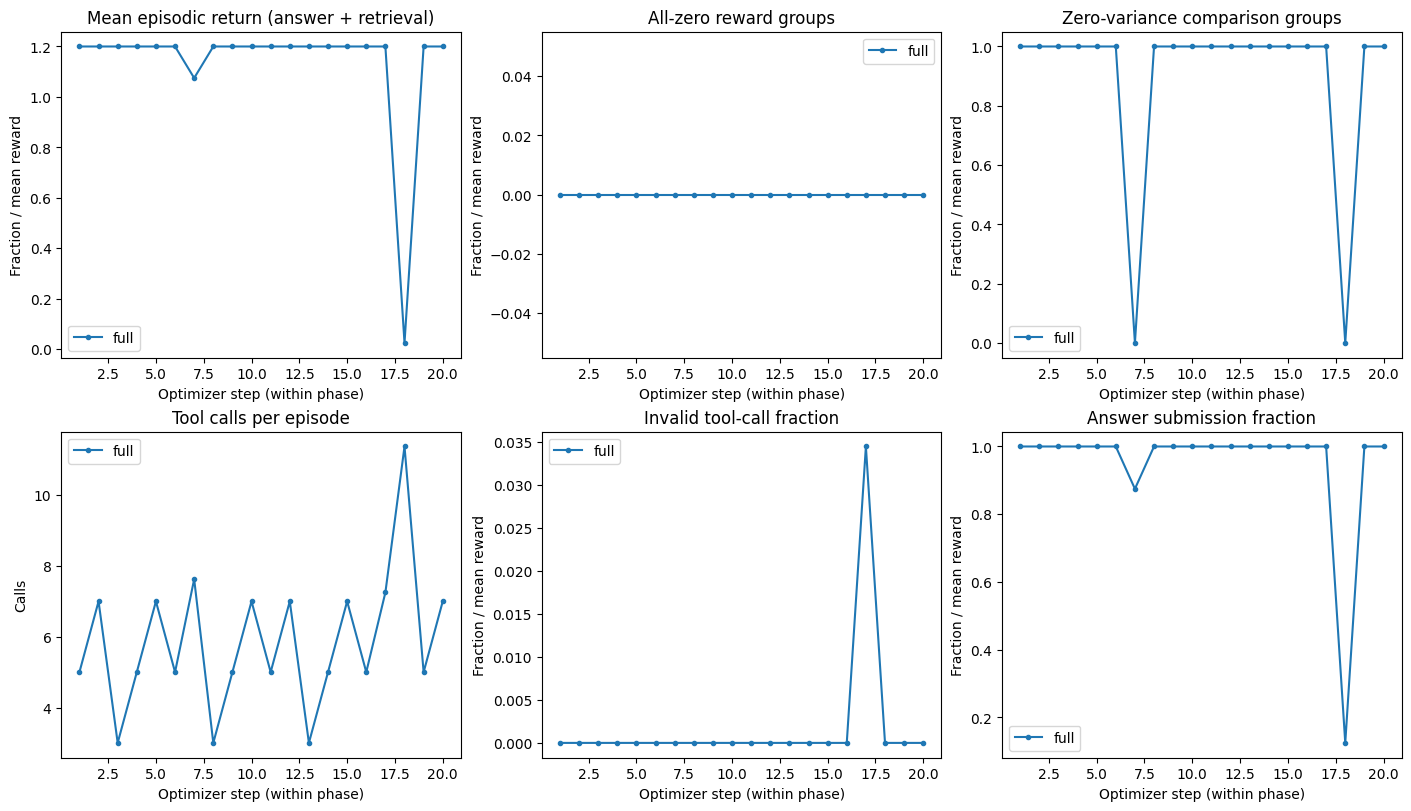

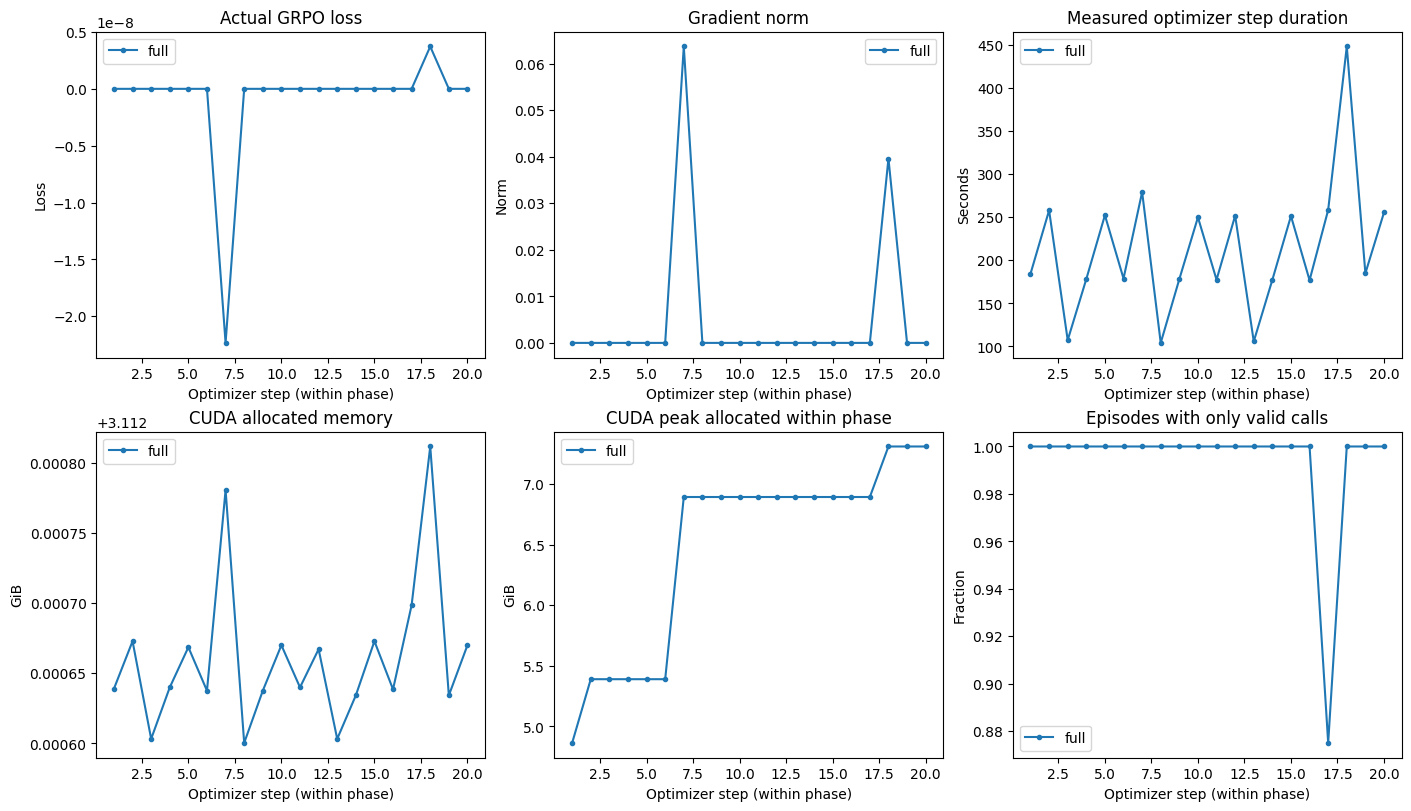

,stage,system_available_gib,cuda_available,allocated_gib,reserved_gib,peak_allocated_gib,peak_reserved_gib
0,before_model,29.588024,True,0.000000,0.000000,0.000000,0.000000
1,after_qlora_load,28.266014,True,3.031675,4.580078,3.578794,4.580078
2,after_baseline,27.907879,True,3.039610,4.583984,3.846089,4.583984
3,after_verified_sft,27.686119,True,3.047544,4.298828,6.076841,10.976562
4,after_sft_only_evaluation,27.714828,True,3.047544,4.320312,6.076841,10.976562
5,after_sft_grpo_full,27.850399,True,3.112669,13.148438,7.310131,13.148438


In [15]:
from IPython.display import Image
sft_grpo_dir = VARIANT_DIRS["sft_grpo"]
rollout_metrics = pd.DataFrame(read_rows(sft_grpo_dir / "rollout_metrics.jsonl"))
trainer_metrics = pd.DataFrame(read_rows(sft_grpo_dir / "trainer_metrics.jsonl"))
step_metrics = pd.DataFrame(read_rows(sft_grpo_dir / "step_metrics.jsonl"))
if not rollout_metrics.empty:
    display(rollout_metrics)
    for name in ["rollout_metrics.png", "optimizer_metrics.png"]:
        path = sft_grpo_dir / "figures" / name
        if path.is_file():
            display(Image(filename=str(path)))
else:
    print("No SFT + GRPO rollout data exists; no metrics are fabricated.")
display(pd.DataFrame(MEMORY))


### Optional test monitoring

`EVALUATE_EVERY_STEPS=0` disables monitoring. When enabled, per-question test rewards are saved separately from training rollouts.

In [16]:
evaluation_metrics = pd.DataFrame(read_rows(sft_grpo_dir / "evaluation_metrics.jsonl"))
evaluation_rewards = pd.DataFrame(read_rows(sft_grpo_dir / "evaluation_rewards.jsonl"))
if not evaluation_metrics.empty:
    display(evaluation_metrics)
    display(evaluation_rewards)
    path = sft_grpo_dir / "figures/evaluation_rewards.png"
    if path.is_file():
        display(Image(filename=str(path)))
else:
    print("No periodic SFT + GRPO test evaluations recorded.")


No periodic SFT + GRPO test evaluations recorded.


<a id="evaluation"></a>
## 11. SFT + GRPO evaluation

Evaluate the same fixed test questions and save results immediately.

In [19]:
SFT_GRPO_METRICS, SFT_GRPO_TRACES = None, []
if RUN_MODEL:
    model = final_trainer.accelerator.unwrap_model(final_trainer.model)
    manifest = full_manifest if FULL_RESULT is not None else smoke_manifest
    export_adapter(
        model,
        tokenizer,
        ADAPTER_DIR,
        manifest,
        extra={
            "experiment_config": EXPERIMENT_CONFIG,
            "smoke_verified": SMOKE_RESULT,
            "full_training_result": FULL_RESULT,
        },
    )
    SFT_GRPO_METRICS, SFT_GRPO_TRACES = evaluate_variant(
        model,
        tokenizer,
        store,
        test_ids,
        LIMITS,
        RUN_ROOT,
        "sft_grpo",
        show_progress=SHOW_PROGRESS,
        training_result={"smoke": SMOKE_RESULT, "full": FULL_RESULT},
    )
    display(pd.Series(SFT_GRPO_METRICS, name="measured SFT + GRPO test").to_frame())
    MEMORY.append(memory_snapshot("after_sft_grpo_evaluation"))
else:
    print("SFT + GRPO test evaluation not run; no accuracy is claimed.")


test:   0%|          | 0/30 [00:00<?, ?question/s]

,measured SFT + GRPO test
episodes,30
mean_reward,0.666667
total_reward,20.0
mean_reward_by_hop,"{'1': 0.875, '2': 0.75, '3': 0.571428571428571..."
mean_training_reward,0.806667
total_training_reward,24.2
mean_training_reward_by_hop,"{'1': 1.075, '2': 0.8999999999999999, '3': 0.6..."
retrieval_success_rate,0.7
mean_retrieval_reward,0.14
accuracy,0.666667


### Inspect SFT + GRPO outputs

Use the same ordered slice as the other variants.

In [20]:
from IPython.display import HTML
from kg_rlvr.training.inspection import render_traces_html

display(HTML(render_traces_html(SFT_GRPO_TRACES, label="SFT + GRPO · test",
    count=INSPECT_EXAMPLES, offset=INSPECT_OFFSET, tokenizer=tokenizer)))


<a id="export"></a>
## 12. Export and reload

Save the adapter and tokenizer, then check a small reloaded sample using the same quantized base.

In [21]:
RELOAD_METRICS, RELOAD_TRACES = None, []
if RUN_MODEL:
    manifest = full_manifest if FULL_RESULT is not None else smoke_manifest
    export_adapter(
        model,
        tokenizer,
        ADAPTER_DIR,
        manifest,
        extra={
            "experiment_config": EXPERIMENT_CONFIG,
            "final_phase": "full" if FULL_RESULT is not None else "smoke",
            "smoke_verified": SMOKE_RESULT,
            "full_training_result": FULL_RESULT,
            "sft_result": SFT_RESULT,
            "vanilla_test_metrics": BASE_METRICS,
            "sft_test_metrics": SFT_METRICS,
            "stage_partition_sha256": STAGE_PARTITION_SHA256,
            "hardware": hardware,
            "sft_grpo_test_metrics": SFT_GRPO_METRICS,
            "evaluation_split": "test",
            "evaluation_task_ids": test_ids,
            "training_logs_directory": str(CHECKPOINT_ROOT),
            "evaluation_directory": str(EVALUATION_DIR),
        },
    )
    for trainer in [full_trainer]:
        if trainer is not None:
            trainer.optimizer = None
            trainer.lr_scheduler = None
            trainer.accelerator.free_memory()
    smoke_trainer = full_trainer = final_trainer = None
    if "trainer" in globals():
        del trainer
    gc.collect()
    torch.cuda.empty_cache()
    model = reload_adapter_in_place(model, ADAPTER_DIR)
    RELOAD_METRICS, RELOAD_TRACES = evaluate_policy(
        model,
        tokenizer,
        store,
        test_ids[:RELOAD_EVAL_SIZE],
        LIMITS,
        EVALUATION_DIR,
        "reloaded_adapter",
        show_progress=SHOW_PROGRESS,
    )
    save_json(VARIANT_DIRS["sft_grpo"] / "memory_snapshots.json", MEMORY)
    display(pd.Series(RELOAD_METRICS, name="measured adapter reload evaluation").to_frame())
    MEMORY.append(memory_snapshot("after_adapter_reload_evaluation"))
    print("Adapter-only export:", ADAPTER_DIR, "Full checkpoints:", CHECKPOINT_ROOT)
else:
    print(
        "No GRPO adapter exported or reloaded: GPU smoke training has not been verified. Any verified SFT adapter is under RUN_ROOT/sft/adapter."
    )


reloaded adapter:   0%|          | 0/3 [00:00<?, ?question/s]

,measured adapter reload evaluation
episodes,3
mean_reward,0.666667
total_reward,2.0
mean_reward_by_hop,"{'1': 0.0, '2': 1.0, '3': 1.0}"
mean_training_reward,0.866667
total_training_reward,2.6
mean_training_reward_by_hop,"{'1': 0.2, '2': 1.2, '3': 1.2}"
retrieval_success_rate,1.0
mean_retrieval_reward,0.2
accuracy,0.666667


Adapter-only export: /kaggle/working/runs/kg_four_variants_seed41/variants/sft_grpo/adapter Full checkpoints: /kaggle/working/checkpoints/kg_four_variants_seed41


<a id="grpo-only"></a>
## 13. GRPO only

Restore the saved untrained adapter. Use the same GRPO pool, exposure, reward and training budget, with no SFT weights.

In [22]:
GRPO_ONLY_SMOKE, GRPO_ONLY_FULL, GRPO_ONLY_METRICS, GRPO_ONLY_TRACES = None, None, None, []
g_only_smoke_trainer = g_only_full_trainer = g_only_final_trainer = None
if RUN_MODEL and RUN_GRPO_ONLY:
    for previous_trainer in [full_trainer, final_trainer]:
        if previous_trainer is not None:
            model = release_trainer(previous_trainer)
    previous_trainer = None
    smoke_trainer = full_trainer = final_trainer = None
    gc.collect()
    torch.cuda.empty_cache()
    model = reload_adapter_in_place(model, INITIAL_ADAPTER_DIR, is_trainable=True)
    GRPO_ONLY_WARM_START = {
        "enabled": False,
        "reserved_sft_ids": sft_ids,
        "stage_partition_sha256": STAGE_PARTITION_SHA256,
        "initial_lora_sha256": INITIAL_LORA_SHA256,
    }
    save_json(VARIANT_DIRS["grpo_only"] / "initialization.json", GRPO_ONLY_WARM_START)
    print("GRPO-only restored the exact vanilla initialization; no SFT adapter weights retained.")
else:
    print("GRPO-only model initialization skipped.")


GRPO-only restored the exact vanilla initialization; no SFT adapter weights retained.


In [24]:
if RUN_MODEL and RUN_GRPO_ONLY and RUN_FULL_TRAINING:
    gc.collect()
    torch.cuda.empty_cache()
    g_only_full_manifest = rl_manifest("grpo_only", GRPO_ONLY_WARM_START)
    g_only_full_trainer, GRPO_ONLY_FULL = run_rl_phase(
        model,
        tokenizer,
        store,
        train_ids,
        LIMITS,
        variant_dir=VARIANT_DIRS["grpo_only"],
        checkpoint_root=GRPO_ONLY_CHECKPOINT_ROOT,
        phase="full",
        steps=INITIAL_TRAINING_STEPS,
        manifest=g_only_full_manifest,
        save_steps=SAVE_STEPS,
        resume_from_checkpoint=GRPO_ONLY_RESUME_FROM_CHECKPOINT,
        **RL_KWARGS
    )
    g_only_final_trainer = g_only_full_trainer
    display(pd.Series(GRPO_ONLY_FULL, name="measured GRPO-only full phase").to_frame())
else:
    print("Full GRPO-only training not run; the measured smoke policy is retained when available.")


/kaggle/working/src/kg_rlvr/training/grpo.py:277: UserWarning: You are using 'rollout_func', which is an experimental feature. This API may change or be removed at any time without prior notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  trainer = GRPOTrainer(model=model, processing_class=tokenizer, args=args, train_dataset=dataset,


full step 1: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

Step,Training Loss
1,0.000000
2,-0.000000
3,0.000000
4,0.000000
5,-0.000000
6,0.000000
7,0.000000
8,0.000000
9,0.000000
10,0.000000


full step 2: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

full step 3: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

...

full step 17: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

full step 18: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

full step 19: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

full step 20: sampling:   0%|          | 0/8 [00:00<?, ?trajectory/s]

,measured GRPO-only full phase
global_step,20
train_loss,0.0
verified_update,None
memory,"{'stage': 'grpo_only_full', 'system_available_..."


### GRPO-only evaluation

Save the adapter, test metrics and trajectories before releasing training objects.

In [26]:
if RUN_MODEL and RUN_GRPO_ONLY:
    model = g_only_final_trainer.accelerator.unwrap_model(g_only_final_trainer.model)
    manifest = g_only_full_manifest if GRPO_ONLY_FULL is not None else g_only_smoke_manifest
    export_adapter(model, tokenizer, VARIANT_DIRS["grpo_only"] / "adapter", manifest,
        extra={"experiment_config": EXPERIMENT_CONFIG, "smoke_verified": GRPO_ONLY_SMOKE, "full_training_result": GRPO_ONLY_FULL})
    GRPO_ONLY_METRICS, GRPO_ONLY_TRACES = evaluate_variant(model, tokenizer, store, test_ids, LIMITS,
        RUN_ROOT, "grpo_only", show_progress=SHOW_PROGRESS,
        training_result={"smoke": GRPO_ONLY_SMOKE, "full": GRPO_ONLY_FULL})
    manifest = g_only_full_manifest if GRPO_ONLY_FULL is not None else g_only_smoke_manifest
    export_adapter(model, tokenizer, VARIANT_DIRS["grpo_only"] / "adapter", manifest,
        extra={"test_metrics": GRPO_ONLY_METRICS, "smoke_verified": GRPO_ONLY_SMOKE,
               "full_training_result": GRPO_ONLY_FULL, "experiment_config": EXPERIMENT_CONFIG})
    save_json(VARIANT_DIRS["grpo_only"] / "memory_snapshots.json", [memory_snapshot("after_grpo_only")])
    display(pd.Series(GRPO_ONLY_METRICS, name="measured GRPO-only test").to_frame())
    display(HTML(render_traces_html(GRPO_ONLY_TRACES, label="GRPO only · test",
        count=INSPECT_EXAMPLES, offset=INSPECT_OFFSET, tokenizer=tokenizer)))
    model = release_trainer(g_only_final_trainer)
    g_only_smoke_trainer = g_only_full_trainer = g_only_final_trainer = None
else:
    print("GRPO-only evaluation not run; no performance is fabricated.")


test:   0%|          | 0/30 [00:00<?, ?question/s]

,measured GRPO-only test
episodes,30
mean_reward,0.5
total_reward,15.0
mean_reward_by_hop,"{'1': 1.0, '2': 0.5, '3': 0.42857142857142855,..."
mean_training_reward,0.62
total_training_reward,18.6
mean_training_reward_by_hop,"{'1': 1.2, '2': 0.6, '3': 0.5142857142857142, ..."
retrieval_success_rate,0.6
mean_retrieval_reward,0.12
accuracy,0.5


### GRPO only · rollout_metrics

,phase,step,mean_episode_reward,success_fraction,zero_reward_group_fraction,zero_variance_group_fraction,answer_zero_variance_group_fraction,episodes,mean_reward,total_reward,...,submission_rate,valid_tool_call_rate,episodes_with_valid_calls_rate,episodes_all_calls_valid_rate,average_tool_calls,average_tool_calls_correct,invalid_tool_call_rate,accuracy_by_hop,termination_reasons,variant
0,full,1,1.050,0.875,0.0,0.0,0.0,8,0.875,7.0,...,1.000,0.950000,1.00,0.750,5.000,5.142857,0.050000,{'2': 0.875},{'submitted': 8},grpo_only
1,full,2,0.300,0.250,0.0,0.0,0.0,8,0.250,2.0,...,0.750,0.971429,0.75,0.750,4.375,7.000000,0.028571,{'3': 0.25},"{'submitted': 6, 'turn_token_limit': 1, 'multi...",grpo_only
2,full,3,0.600,0.500,0.0,0.0,0.0,8,0.500,4.0,...,0.500,1.000000,0.50,0.500,1.500,3.000000,0.000000,{'1': 0.5},"{'turn_token_limit': 4, 'submitted': 4}",grpo_only
3,full,4,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,0.952381,1.00,0.750,5.250,5.250000,0.047619,{'2': 1.0},{'submitted': 8},grpo_only
4,full,5,0.600,0.500,0.0,0.0,0.0,8,0.500,4.0,...,0.500,1.000000,0.50,0.500,3.500,7.000000,0.000000,{'3': 0.5},"{'turn_token_limit': 4, 'submitted': 4}",grpo_only
5,full,6,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,0.975610,1.00,0.875,5.125,5.125000,0.024390,{'2': 1.0},{'submitted': 8},grpo_only
6,full,7,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,0.883117,1.00,0.625,9.625,9.625000,0.116883,{'3': 1.0},{'submitted': 8},grpo_only
7,full,8,0.650,0.500,0.0,0.0,0.0,8,0.500,4.0,...,0.500,0.944444,0.75,0.500,4.500,3.000000,0.055556,{'1': 0.5},"{'submitted': 4, 'turn_token_limit': 2, 'tool_...",grpo_only
8,full,9,1.200,1.000,0.0,1.0,1.0,8,1.000,8.0,...,1.000,0.952381,1.00,0.750,5.250,5.250000,0.047619,{'2': 1.0},{'submitted': 8},grpo_only
9,full,10,0.000,0.000,1.0,1.0,1.0,8,0.000,0.0,...,1.000,1.000000,1.00,1.000,5.000,NaN,0.000000,{'3': 0.0},{'submitted': 8},grpo_only


### GRPO only · trainer_metrics

,step,loss,grad_norm,learning_rate,num_tokens,completions/mean_length,completions/min_length,completions/max_length,completions/clipped_ratio,completions/mean_terminated_length,...,clip_ratio/region_mean,step_time,epoch,phase,variant,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1,4.842877e-08,0.218769,0.000005,6106.0,156.250,115.0,181.0,0.000,156.250000,...,0.0,177.120712,0.05,full,grpo_only,NaN,NaN,NaN,NaN,NaN
1,2,-1.490116e-08,0.179566,0.000005,12300.0,162.250,84.0,225.0,0.125,167.142868,...,0.0,184.178990,0.10,full,grpo_only,NaN,NaN,NaN,NaN,NaN
2,3,0.000000e+00,0.319066,0.000005,18040.0,111.500,95.0,128.0,0.500,95.000000,...,0.0,123.320456,0.15,full,grpo_only,NaN,NaN,NaN,NaN,NaN
3,4,0.000000e+00,0.000000,0.000005,24228.0,164.500,159.0,181.0,0.000,164.500000,...,0.0,183.974505,0.20,full,grpo_only,NaN,NaN,NaN,NaN,NaN
4,5,-3.725290e-08,0.179173,0.000005,30548.0,177.000,128.0,226.0,0.500,226.000000,...,0.0,199.918454,0.25,full,grpo_only,NaN,NaN,NaN,NaN,NaN
5,6,0.000000e+00,0.000000,0.000005,36721.0,164.625,160.0,197.0,0.000,164.625000,...,0.0,184.718191,0.30,full,grpo_only,NaN,NaN,NaN,NaN,NaN
6,7,0.000000e+00,0.000000,0.000005,44133.0,318.500,224.0,409.0,0.000,318.500000,...,0.0,367.065968,0.35,full,grpo_only,NaN,NaN,NaN,NaN,NaN
7,8,3.725290e-08,0.342487,0.000005,50372.0,175.875,92.0,392.0,0.250,191.833344,...,0.0,208.024695,0.40,full,grpo_only,NaN,NaN,NaN,NaN,NaN
8,9,0.000000e+00,0.000000,0.000005,56554.0,165.750,160.0,183.0,0.000,165.750000,...,0.0,186.776603,0.45,full,grpo_only,NaN,NaN,NaN,NaN,NaN
9,10,0.000000e+00,0.000000,0.000005,62738.0,159.000,159.0,159.0,0.000,159.000000,...,0.0,181.038103,0.50,full,grpo_only,NaN,NaN,NaN,NaN,NaN


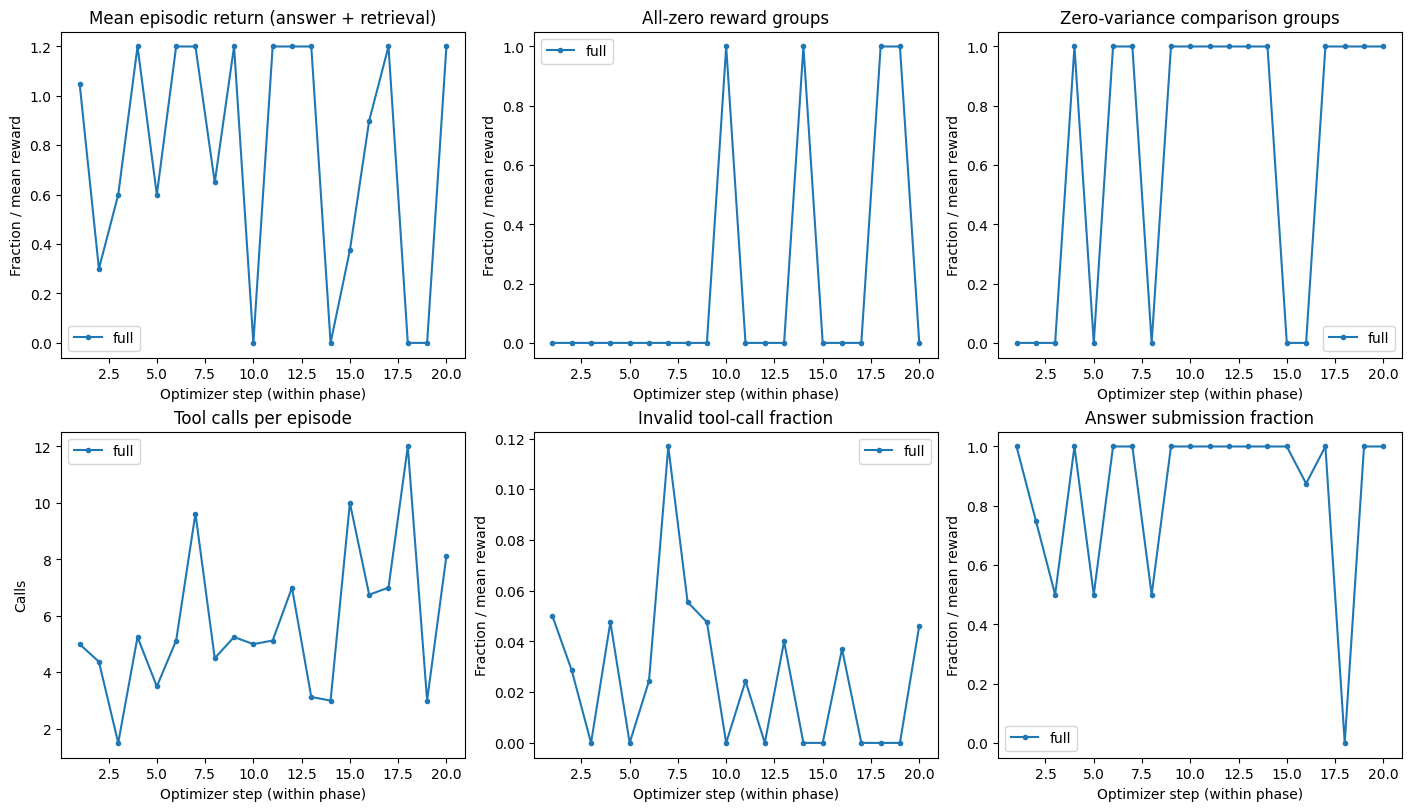

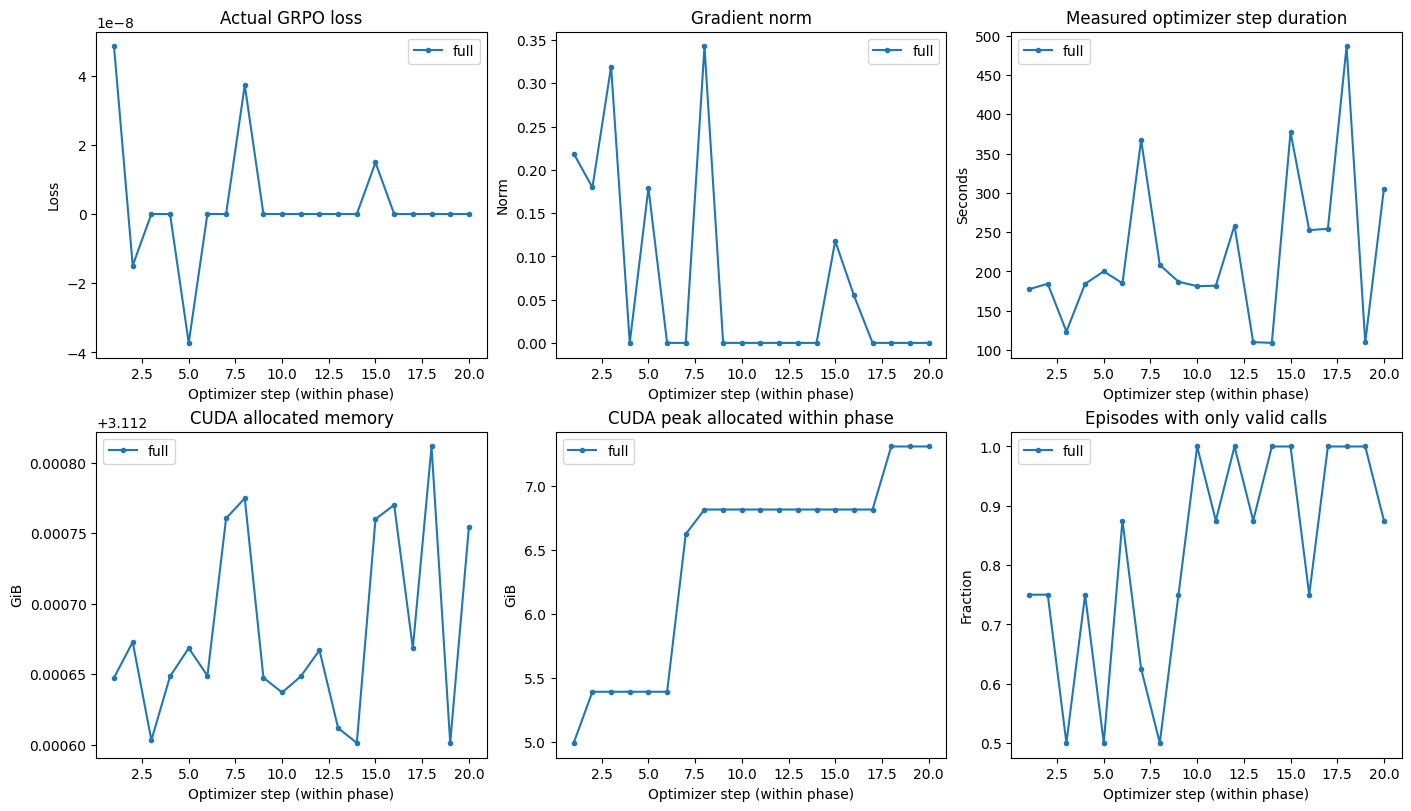

In [27]:
g_only_dir = VARIANT_DIRS["grpo_only"]
for name in ["rollout_metrics", "trainer_metrics", "evaluation_metrics", "evaluation_rewards"]:
    rows = read_rows(g_only_dir / (name + ".jsonl"))
    if rows:
        display(Markdown(f"### GRPO only · {name}"))
        display(pd.DataFrame(rows))
for name in ["rollout_metrics.png", "optimizer_metrics.png", "evaluation_rewards.png"]:
    path = g_only_dir / "figures" / name
    if path.is_file():
        display(Image(filename=str(path)))
g_only_training_traces = read_rows(g_only_dir / "training_trajectories.jsonl")
display(HTML(render_traces_html(g_only_training_traces, label="GRPO only · sampled training episodes",
    count=INSPECT_EXAMPLES, offset=INSPECT_OFFSET, tokenizer=tokenizer)))


<a id="comparison"></a>
## 14. Compare variants

All results use the same test questions. Thirty questions and one seed describe this run; they do not establish a general ranking.

In [28]:
comparison = pd.DataFrame(save_comparison(RUN_ROOT))
display(comparison)
for variant, directory in VARIANT_DIRS.items():
    status_path = directory / "status.json"
    if status_path.is_file():
        display(pd.Series(json.loads(status_path.read_text()), name=variant).to_frame())
print("Separate policy artifacts:", RUN_ROOT / "variants")


,metric,Vanilla,SFT,SFT + GRPO,GRPO only
0,1-hop test accuracy,0.500000,0.500000,0.875000,1.000000
1,2-hop test accuracy,0.000000,0.750000,0.750000,0.500000
2,3-hop test accuracy,0.000000,0.571429,0.571429,0.428571
3,4-hop test accuracy,0.000000,0.285714,0.428571,0.000000
4,accuracy,0.133333,0.533333,0.666667,0.500000
5,mean_reward,0.133333,0.533333,0.666667,0.500000
6,mean_training_reward,0.160000,0.666667,0.806667,0.620000
7,retrieval_success_rate,0.133333,0.666667,0.700000,0.600000
8,valid_tool_call_rate,0.906250,0.965217,0.971831,0.984615
9,episodes_with_valid_calls_rate,0.300000,1.000000,1.000000,1.000000


,vanilla
variant,vanilla
evaluation_split,test
evaluation_task_ids,"[q_003492, q_002025, q_002129, q_002709, q_003..."
training_result,None
evaluation_complete,True
status,complete


,sft
variant,sft
evaluation_split,test
evaluation_task_ids,"[q_003492, q_002025, q_002129, q_002709, q_003..."
training_result,"{'optimizer_steps': 13, 'changed_lora_tensors'..."
evaluation_complete,True
status,complete


,sft_grpo
variant,sft_grpo
evaluation_split,test
evaluation_task_ids,"[q_003492, q_002025, q_002129, q_002709, q_003..."
training_result,"{'smoke': None, 'full': {'global_step': 20, 't..."
evaluation_complete,True
status,complete


,grpo_only
variant,grpo_only
evaluation_split,test
evaluation_task_ids,"[q_003492, q_002025, q_002129, q_002709, q_003..."
training_result,"{'smoke': None, 'full': {'global_step': 20, 't..."
evaluation_complete,True
status,complete


Separate policy artifacts: /kaggle/working/runs/kg_four_variants_seed41/variants


## 15. Slide figures

Load saved results, then render the original accuracy and total-return plots. Confidence bands describe sampled questions within this run.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from functools import partial
from IPython.display import FileLink
from kg_rlvr.training import presentation as slides

ROOT = RUN_ROOT
OUT = ROOT / "slide_figures"
OUT.mkdir(parents=True, exist_ok=True)
VARIANTS, STYLE = slides.VARIANTS, slides.STYLE
WINDOW_STEPS = 5
finish_axis = slides.finish_axis
export = partial(slides.export, directory=OUT)
return_ci = slides.return_ci
evaluations, training = slides.load_results(ROOT, WINDOW_STEPS)


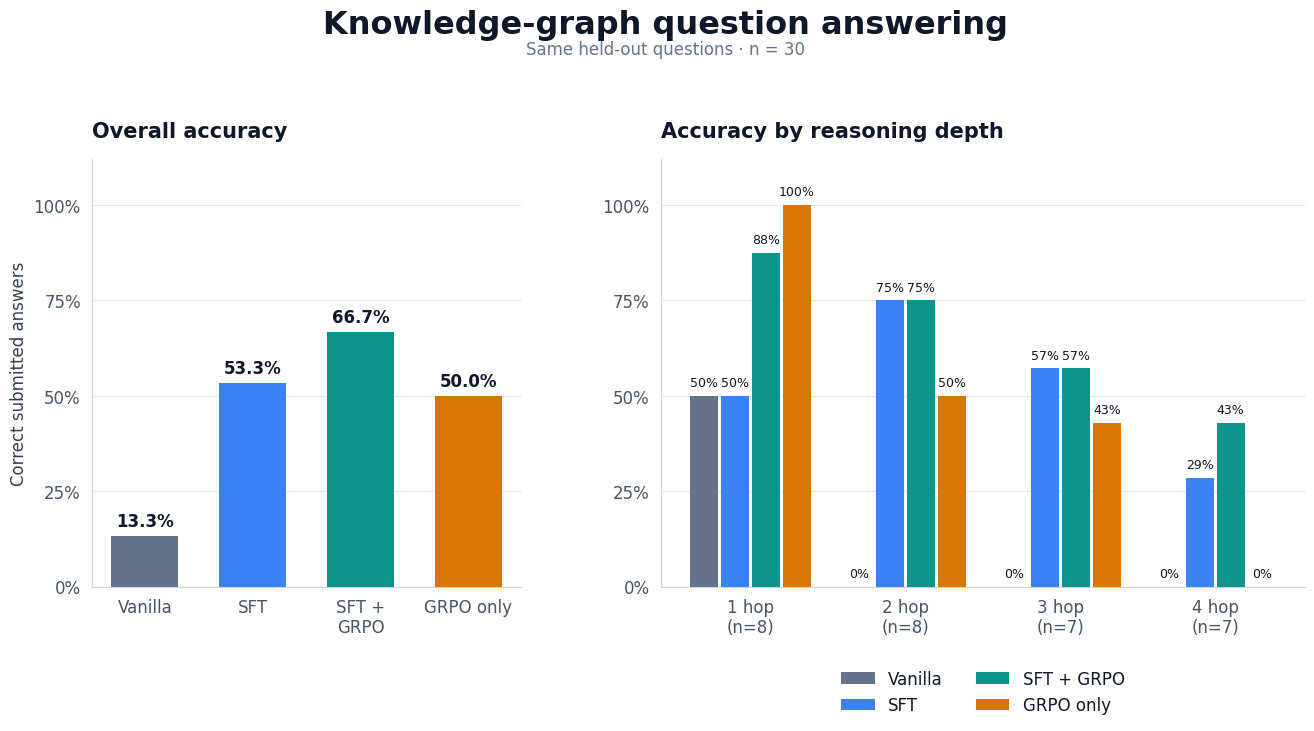

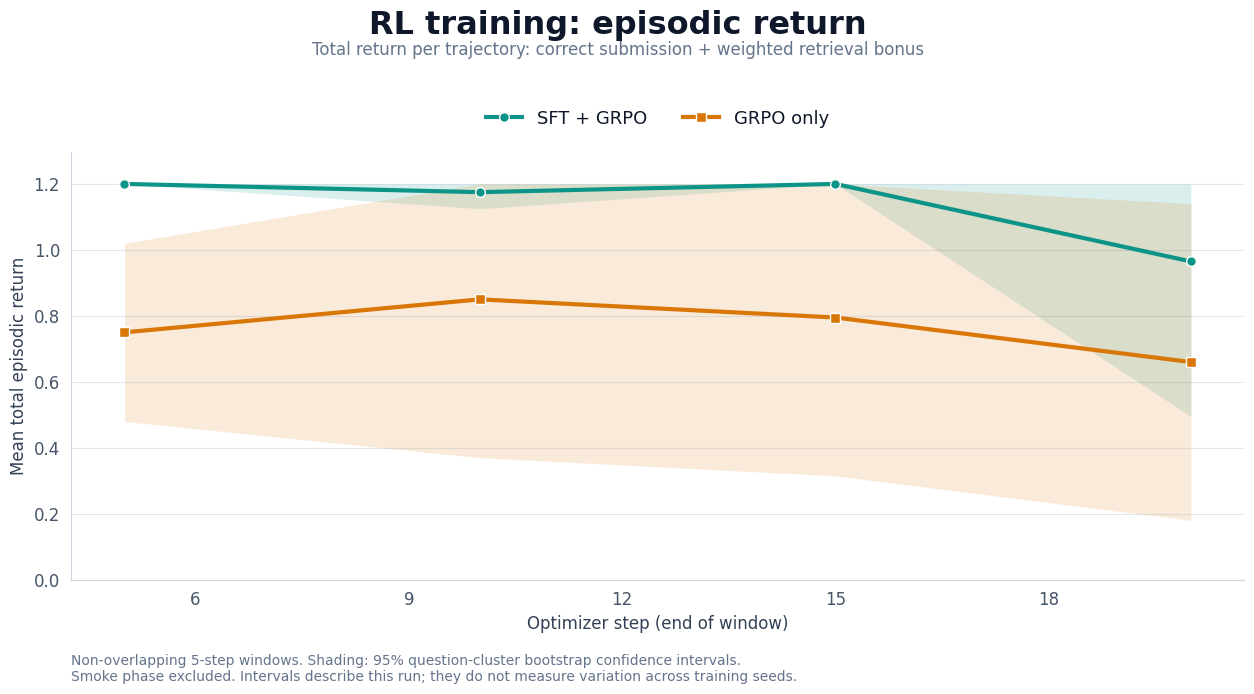

Updated figures: /kaggle/working/runs/kg_four_variants_seed41/slide_figures


/kaggle/working/runs/kg_four_variants_seed41/slide_figures/01_test_accuracy.pdf

/kaggle/working/runs/kg_four_variants_seed41/slide_figures/01_test_accuracy.png

/kaggle/working/runs/kg_four_variants_seed41/slide_figures/01_test_accuracy.svg

/kaggle/working/runs/kg_four_variants_seed41/slide_figures/02_rl_episodic_return.pdf

/kaggle/working/runs/kg_four_variants_seed41/slide_figures/02_rl_episodic_return.png

/kaggle/working/runs/kg_four_variants_seed41/slide_figures/02_rl_episodic_return.svg

/kaggle/working/runs/kg_four_variants_seed41/slide_figures/rl_return_windows.csv

/kaggle/working/runs/kg_four_variants_seed41/slide_figures/test_accuracy.csv

In [31]:
# Reuses evaluations, training, VARIANTS, STYLE, OUT,
# finish_axis(), export(), return_ci(), and WINDOW_STEPS
# from the previous visualization cell.

# ── 1. Accuracy: no confidence intervals ──────────────────────────────

if evaluations:
    keys = list(evaluations)
    reference = next(iter(evaluations.values()))
    hops = sorted(reference["hop_count"].unique())
    accuracy_rows = []

    with plt.rc_context(STYLE):
        fig, (ax0, ax1) = plt.subplots(
            1, 2,
            figsize=(13.33, 7.5),
            gridspec_kw={"width_ratios": [1, 1.5]},
        )
        fig.subplots_adjust(
            left=.07, right=.98, bottom=.19,
            top=.76, wspace=.26,
        )
        fig.suptitle(
            "Knowledge-graph question answering",
            fontsize=23, fontweight="bold", y=.96,
        )
        fig.text(
            .5, .90,
            f"Same held-out questions · n = {len(reference)}",
            ha="center", color="#64748B",
        )

        width = .8 / len(keys)

        for i, variant in enumerate(keys):
            label, color = VARIANTS[variant]
            frame = evaluations[variant]
            accuracy = frame["answer"].mean()

            ax0.bar(
                i, accuracy, width=.62,
                color=color, zorder=3,
            )
            ax0.text(
                i, accuracy + .025,
                f"{accuracy:.1%}",
                ha="center", fontweight="bold", fontsize=12,
            )
            accuracy_rows.append({
                "variant": label,
                "category": "Overall",
                "n": len(frame),
                "accuracy": accuracy,
            })

            for j, hop in enumerate(hops):
                subset = frame[frame["hop_count"] == hop]
                accuracy = subset["answer"].mean()
                x = j - .4 + width * (i + .5)

                ax1.bar(
                    x, accuracy, width=width * .9,
                    color=color,
                    label=label if j == 0 else None,
                    zorder=3,
                )
                ax1.text(
                    x, accuracy + .025,
                    f"{accuracy:.0%}",
                    ha="center", fontsize=9,
                )
                accuracy_rows.append({
                    "variant": label,
                    "category": f"{int(hop)} hop",
                    "n": len(subset),
                    "accuracy": accuracy,
                })

        ax0.set_xticks(
            range(len(keys)),
            [
                VARIANTS[v][0].replace(" + ", " +\n")
                for v in keys
            ],
        )
        ax1.set_xticks(
            range(len(hops)),
            [
                f"{int(h)} hop\n"
                f"(n={(reference['hop_count'] == h).sum()})"
                for h in hops
            ],
        )
        ax0.set_title(
            "Overall accuracy",
            loc="left", fontweight="bold", pad=16,
        )
        ax1.set_title(
            "Accuracy by reasoning depth",
            loc="left", fontweight="bold", pad=16,
        )
        ax0.set_ylabel("Correct submitted answers")

        for ax in (ax0, ax1):
            finish_axis(ax)
            ax.set_ylim(0, 1.12)
            ax.set_yticks(np.linspace(0, 1, 5))
            ax.yaxis.set_major_formatter(PercentFormatter(1))

        ax1.legend(
            frameon=False,
            loc="upper center",
            bbox_to_anchor=(.5, -.16),
            ncol=2,
        )
        export(fig, "01_test_accuracy")

    pd.DataFrame(accuracy_rows).to_csv(
        OUT / "test_accuracy.csv", index=False
    )


# ── 2. Shared RL plot: total episodic return only ─────────────────────

if training:
    return_rows = []
    markers = {"sft_grpo": "o", "grpo_only": "s"}

    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(13.33, 7.5))
        fig.subplots_adjust(
            left=.09, right=.97,
            bottom=.20, top=.77,
        )
        fig.suptitle(
            "RL training: episodic return",
            fontsize=23, fontweight="bold", y=.96,
        )
        fig.text(
            .5, .90,
            "Total return per trajectory: "
            "correct submission + weighted retrieval bonus",
            ha="center", color="#64748B",
        )

        ymax = max(
            1.25,
            max(
                frame["return"].max()
                for frame in training.values()
            ) * 1.08,
        )

        for variant in ["sft_grpo", "grpo_only"]:
            if variant not in training:
                continue

            frame = training[variant]
            label, color = VARIANTS[variant]
            rows = []

            for _, group in frame.groupby("window", sort=True):
                mean, lo, hi, clusters = return_ci(group)
                rows.append({
                    "variant": label,
                    "step": group["step"].max(),
                    "first_step": group["step"].min(),
                    "episodes": len(group),
                    "question_clusters": clusters,
                    "mean_return": mean,
                    "ci_low": lo,
                    "ci_high": hi,
                })

            curve = pd.DataFrame(rows)
            return_rows.extend(rows)
            x = curve["step"].to_numpy(dtype=float)

            ax.plot(
                x,
                curve["mean_return"],
                label=label,
                color=color,
                linewidth=3,
                marker=markers[variant],
                markersize=7,
                markeredgecolor="white",
                markeredgewidth=1,
                zorder=3,
            )
            ax.fill_between(
                x,
                curve["ci_low"].to_numpy(dtype=float),
                curve["ci_high"].to_numpy(dtype=float),
                color=color,
                alpha=.15,
                linewidth=0,
                zorder=2,
            )

        finish_axis(ax)
        ax.set_xlabel("Optimizer step (end of window)")
        ax.set_ylabel("Mean total episodic return")
        ax.set_ylim(0, ymax)
        ax.xaxis.set_major_locator(
            MaxNLocator(integer=True, nbins=8)
        )
        ax.legend(
            loc="lower center",
            bbox_to_anchor=(.5, 1.02),
            ncol=2,
            frameon=False,
            fontsize=13,
        )

        fig.text(
            .09, .065,
            f"Non-overlapping {WINDOW_STEPS}-step windows. "
            "Shading: 95% question-cluster bootstrap confidence intervals.\n"
            "Smoke phase excluded. Intervals describe this run; "
            "they do not measure variation across training seeds.",
            fontsize=10,
            color="#64748B",
        )
        export(fig, "02_rl_episodic_return")

    pd.DataFrame(return_rows).to_csv(
        OUT / "rl_return_windows.csv", index=False
    )


print("Updated figures:", OUT)
for path in sorted(OUT.glob("*")):
    if path.suffix in {".png", ".svg", ".pdf", ".csv"}:
        display(FileLink(str(path)))

<a id="zip-heading"></a>
## 16. Download

Package the already saved results and slide figures. Full checkpoints and model caches remain separate.

In [29]:
from kg_rlvr.training.artifacts import zip_run_artifacts
from IPython.display import FileLink

if MAKE_ZIP:
    zip_path = zip_run_artifacts(RUN_ROOT, WORK_ROOT / f"{RUN_NAME}_variants_and_diagnostics.zip")
    print("Download from the Kaggle output panel:", zip_path)
    display(FileLink(str(zip_path)))
else:
    print("ZIP creation disabled; per-variant files are already saved under", RUN_ROOT)


Download from the Kaggle output panel: /kaggle/working/kg_four_variants_seed41_variants_and_diagnostics.zip


/kaggle/working/kg_four_variants_seed41_variants_and_diagnostics.zip